# PiDiNet edge enhancement, weight 0.25 (BTXRD, deep learning)
Enhances the edges of every X-ray with **PiDiNet**, a deep learning edge detector, **at its full size** (2440 x 2440), and only then makes it 512 x 512 (the same way as notebook 07). Everything else is the same as in the classical notebooks.
The new images are saved as PNG in **`BTXRD_pidinet_512_weight0-25.zip`**. Inside the zip are the same `train`, `validation` and `test` folders, each with `normal` and `tumor`, as in `BTXRD_512.zip`. Every image stays in the same split as before. The original data is only read, never changed.

**PiDiNet** (Su et al., 2021, *Pixel Difference Networks for Efficient Edge Detection*, ICCV) is a small network that learned to find the outlines of objects. This notebook uses the authors' own trained model `table5_pidinet.pth` from github.com/hellozhuo/pidinet. It was trained on everyday photos (the BSDS500 edge dataset), not on X-rays, and it is not trained again here. It is used as in the authors' code: the X-ray as a 3-channel image, pixels 0-1, the ImageNet mean and spread taken away, and the last output (the fused edge map). The authors' simpler "converted" form of the network is used, which they state gives the same results and is faster.

**The edge map is added to the X-ray at a quarter of white** (`EDGE_WEIGHT = 0.25`). So the edges stand out while the rest of the X-ray stays the same.

**Why 0.25.** The first run, `pidinet_btxrd.ipynb`, used 0.5, the same number as the Canny notebook. But Canny's lines are very thin and mostly fade when the image shrinks, while PiDiNet's lines are thick and stay. So 0.5 changed the image much more than the classical edge methods (at 512 x 512: PSNR 18.8, SSIM 0.659, CII 0.868; Canny PSNR 31.3, Sobel PSNR 25.2). Here the edges are half as strong. The value was chosen to bring the change closer to the classical methods, not from any model result. Letters like "R" are found as edges too, as with Canny and Sobel.

**Only the box around the X-ray goes through the network**, not the black square around it. Outside the box the image stays as it is.

Time: about 35-45 minutes on a T4 GPU (estimated from the first run).
## Before you run
1. **In Google Drive**, the folder `BTXRD` (in *My Drive*) must hold `BTXRD_full.zip` and `BTXRD_512.zip`. You already uploaded them for the noise notebooks.
2. **In Colab**: *Runtime > Change runtime type > T4 GPU*, then *Run all*, and allow access to Google Drive.
3. **If Colab disconnects**, just *Run all* again: every finished image is already saved in Drive (folder `BTXRD/BTXRD_pidinet_512_weight0-25`) and is skipped.
4. **At the end**, download `BTXRD_pidinet_512_weight0-25.zip` and `BTXRD_pidinet_512_weight0-25_full_size_scores.csv` (last cell, or from the Drive folder `BTXRD`) and put them in this folder, next to this notebook. Then save this notebook with its outputs: *File > Download > Download .ipynb*. (In Safari, first untick *Settings > General > Open "safe" files after downloading*, or the zip gets unpacked.)

## Settings

In [1]:
import io
import json
import os
import shutil
import time
import zipfile
from collections import Counter
from pathlib import Path

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"           # needed for repeatable GPU results (set before torch starts)

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from google.colab import drive

drive.mount("/content/drive")
DRIVE = Path("/content/drive/MyDrive/BTXRD")               # your Google Drive folder with the 2 zips
FULL_ZIP = DRIVE / "BTXRD_full.zip"                        # the full-size images: train, validation, test, Annotations (only read)
OLD_ZIP_DRIVE = DRIVE / "BTXRD_512.zip"                    # the baseline zip (only read)
LOCAL = Path("/content/btxrd_full")                        # the full-size images are unzipped here (the fast local disk)
OLD_ZIP = Path("/content/BTXRD_512.zip")                   # a local copy of the baseline zip
NAME = "BTXRD_pidinet_512_weight0-25"                                 # the name of the new zip and of the folder inside it
OUT_DIR = DRIVE / NAME                                     # the finished 512 x 512 PNGs, kept in Drive, so a disconnect loses nothing
NEW_ZIP = Path("/content") / (NAME + ".zip")               # the new zip, made at the end (and copied to Drive)
SPLITS = ["train", "validation", "test"]
MALIGNANT = {"osteosarcoma", "other mt"}               # all other tumor types are benign

SIZE = (512, 512)    # the same size as the baseline
EDGE_WEIGHT = 0.25   # PiDiNet: the edge map is added at a quarter of white (0.25 x 255)
WEIGHTS_URL = "https://raw.githubusercontent.com/hellozhuo/pidinet/d21aa881ed9c628571636fad39acfe1fad517ebd/trained_models/table5_pidinet.pth"   # the authors' trained model
WEIGHTS = Path("/content/table5_pidinet.pth")
BLACK = 15           # pixels at or below this are black background
RING = 10            # CII: width of the ring around the tumor, in pixels (on the 512 x 512 image)
RING_FULL = 48       # CII at full size: the same ring, 48 pixels wide on the 2440 x 2440 image (10 x 2440 / 512)
FULL_SCORES = DRIVE / (NAME + "_full_size_scores.csv")     # the full-size scores, one line per image, kept in Drive
SEED = 42            # makes the random parts the same every time

Mounted at /content/drive


## GPU, settings for repeatable results, and the data
Checks the GPU, unzips the full-size images to the fast local disk, and finds the data folders.

In [2]:
assert torch.cuda.is_available(), "No GPU: choose Runtime > Change runtime type > T4 GPU, then run again"
DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

torch.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True                  # the same GPU calculations every time
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False                    # full 32-bit precision, also on newer GPUs
torch.backends.cuda.matmul.allow_tf32 = False
torch.use_deterministic_algorithms(True, warn_only=True)   # repeatable where possible (only warns otherwise)

for f in [FULL_ZIP, OLD_ZIP_DRIVE]:
    assert f.exists(), f"Upload {f.name} to the Google Drive folder {DRIVE} first"

if not (LOCAL / "unzipped.txt").exists():                  # skipped when this runtime already has them
    shutil.rmtree(LOCAL, ignore_errors=True)
    local_zip = Path("/content/BTXRD_full.zip")
    shutil.copy(FULL_ZIP, local_zip)                       # copy from Drive first: the local disk is much faster
    with zipfile.ZipFile(local_zip) as z:
        z.extractall(LOCAL)
    local_zip.unlink()
    (LOCAL / "unzipped.txt").write_text("done")
if not OLD_ZIP.exists():
    shutil.copy(OLD_ZIP_DRIVE, OLD_ZIP)


def find_data(folder):
    for annotations in sorted(folder.rglob("Annotations")):
        root = annotations.parent
        if "__MACOSX" not in root.parts and all((root / split).is_dir() for split in SPLITS):
            return root
    raise FileNotFoundError("BTXRD_full.zip must hold the folders train, validation, test and Annotations")


DATA = find_data(LOCAL)                                    # the original full-size images without duplicates (only read)
ANNOTATIONS = DATA / "Annotations"                         # tumor outlines (only read)
print("Full-size images:", DATA)

GPU: Tesla T4
Full-size images: /content/btxrd_full


## List the images
Every image in the `train`, `validation` and `test` folders, with its split, label (normal or tumor) and group (normal, benign or malignant).

In [3]:
def tumor_type(path):
    annotation = ANNOTATIONS / (path.stem + ".json")
    if not annotation.exists():
        return ""                                              # normal images have no annotation
    return json.loads(annotation.read_text())["shapes"][0]["label"]


records = []
for split in SPLITS:
    for path in sorted((DATA / split).glob("*/*.jp*g")):       # */ = normal or tumor, files end in .jpeg or .jpg
        if path.name.startswith("._"):
            continue                                           # hidden Mac files, not X-rays
        kind = tumor_type(path)
        if kind == "":
            group = "normal"
        elif kind in MALIGNANT:
            group = "malignant"
        else:
            group = "benign"
        records.append({"image": path.stem, "split": split, "label": path.parent.name, "group": group, "path": path})

images = pd.DataFrame(records)
print(len(images), "images")
print(images.groupby(["split", "label"]).size())

3723 images
split       label 
test        normal     280
            tumor      279
train       normal    1306
            tumor     1300
validation  normal     280
            tumor      278
dtype: int64


## Check: the same split as `BTXRD_512.zip`
Every image must be in the same split (train, validation or test) and have the same label as in the baseline zip. If not, the notebook stops here.

In [4]:
old_zip = zipfile.ZipFile(OLD_ZIP)                         # kept open: the baseline images are read from it later
old_names = {name.removeprefix("BTXRD_512/").removesuffix(".png")   # for example train/normal/IMG001868
             for name in old_zip.namelist() if name.endswith(".png")}
names = set(images["split"] + "/" + images["label"] + "/" + images["image"])

print("Images in BTXRD_512.zip:", len(old_names), "| images here:", len(names))
print("Same split and label for every image:", names == old_names)
assert names == old_names, "the split is not the same as in BTXRD_512.zip"

Images in BTXRD_512.zip: 3723 | images here: 3723
Same split and label for every image: True


## Functions
Load an image at full size, make an image 512 x 512 (the same way as notebook 07), read a baseline image, and find the X-ray inside the black square.

In [5]:
def load(path):
    image = Image.open(path).convert("L")                      # gray, pixels 0 (black) to 255 (white)
    return np.array(image)                                     # full size: 2440 x 2440


def shrink(image):
    image = Image.fromarray(image).resize(SIZE, Image.LANCZOS)  # 512 x 512, the same way as notebook 07
    return np.array(image)


def baseline(item):
    path = f"BTXRD_512/{item['split']}/{item['label']}/{item['image']}.png"
    return np.array(Image.open(io.BytesIO(old_zip.read(path))))   # the baseline image the models were trained on


def xray_box(image):
    rows = np.where((image > BLACK).any(axis=1))[0]            # rows with something brighter than black
    cols = np.where((image > BLACK).any(axis=0))[0]            # the same for columns
    return rows[0], rows[-1] + 1, cols[0], cols[-1] + 1        # top, bottom, left, right

## Check: Colab makes 512 x 512 images exactly like the baseline
The baseline images were made on the Mac. If Colab's image library shrank images even a little differently, part of the difference would come from that and not from the method. So 25 images are shrunk here and must be exactly the same as in `BTXRD_512.zip`.

In [6]:
sample = images.sample(25, random_state=SEED)
same = [np.array_equal(shrink(load(item["path"])), baseline(item)) for _, item in sample.iterrows()]
print("Made 512 x 512 exactly like BTXRD_512.zip:", sum(same), "of", len(same))
assert all(same), "This Pillow version resizes differently: run  !pip install pillow==12.3.0  then Runtime > Restart, and run again"

Made 512 x 512 exactly like BTXRD_512.zip: 25 of 25


## The PiDiNet model
The same network as in the authors' code, loaded with their trained weights. `strict=True` and the count of weights check that the file and the network match exactly. Only the box around the X-ray goes through the network.

In [7]:
class CSAM(nn.Module):                                         # the authors' attention part (models/pidinet.py)
    def __init__(self, channels):
        super().__init__()
        self.relu1 = nn.ReLU()
        self.conv1 = nn.Conv2d(channels, 4, kernel_size=1, padding=0)
        self.conv2 = nn.Conv2d(4, 1, kernel_size=3, padding=1, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        y = self.relu1(x)
        y = self.conv1(y)
        y = self.conv2(y)
        y = self.sigmoid(y)
        return x * y


class CDCM(nn.Module):                                         # the authors' part that looks at 4 distances at once
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.relu1 = nn.ReLU()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=1, padding=0)
        self.conv2_1 = nn.Conv2d(out_channels, out_channels, kernel_size=3, dilation=5, padding=5, bias=False)
        self.conv2_2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, dilation=7, padding=7, bias=False)
        self.conv2_3 = nn.Conv2d(out_channels, out_channels, kernel_size=3, dilation=9, padding=9, bias=False)
        self.conv2_4 = nn.Conv2d(out_channels, out_channels, kernel_size=3, dilation=11, padding=11, bias=False)

    def forward(self, x):
        x = self.relu1(x)
        x = self.conv1(x)
        return self.conv2_1(x) + self.conv2_2(x) + self.conv2_3(x) + self.conv2_4(x)


class MapReduce(nn.Module):                                    # makes one edge map from many channels
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, 1, kernel_size=1, padding=0)

    def forward(self, x):
        return self.conv(x)


class PDCBlock(nn.Module):                                     # PDCBlock_converted in the authors' code
    def __init__(self, kind, in_channels, out_channels, stride=1):
        super().__init__()
        self.stride = stride
        if stride > 1:
            self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
            self.shortcut = nn.Conv2d(in_channels, out_channels, kernel_size=1, padding=0)
        size = 5 if kind == "rd" else 3                        # the "rd" pixel difference becomes a 5 x 5 convolution
        self.conv1 = nn.Conv2d(in_channels, in_channels, kernel_size=size, padding=size // 2, groups=in_channels, bias=False)
        self.relu2 = nn.ReLU()
        self.conv2 = nn.Conv2d(in_channels, out_channels, kernel_size=1, padding=0, bias=False)

    def forward(self, x):
        if self.stride > 1:
            x = self.pool(x)
        y = self.conv1(x)
        y = self.relu2(y)
        y = self.conv2(y)
        if self.stride > 1:
            x = self.shortcut(x)
        return y + x


KINDS = ["cd", "ad", "rd", "cv"] * 4                           # the "carv4" setting: which pixel difference each of the 16 layers uses


class PiDiNet(nn.Module):                                      # PiDiNet(60, dil=24, sa=True, convert=True) in the authors' code
    def __init__(self, c=60, dil=24):
        super().__init__()
        self.init_block = nn.Conv2d(3, c, kernel_size=3, padding=1, bias=False)
        self.block1_1 = PDCBlock(KINDS[1], c, c)
        self.block1_2 = PDCBlock(KINDS[2], c, c)
        self.block1_3 = PDCBlock(KINDS[3], c, c)
        self.block2_1 = PDCBlock(KINDS[4], c, 2 * c, stride=2)
        self.block2_2 = PDCBlock(KINDS[5], 2 * c, 2 * c)
        self.block2_3 = PDCBlock(KINDS[6], 2 * c, 2 * c)
        self.block2_4 = PDCBlock(KINDS[7], 2 * c, 2 * c)
        self.block3_1 = PDCBlock(KINDS[8], 2 * c, 4 * c, stride=2)
        self.block3_2 = PDCBlock(KINDS[9], 4 * c, 4 * c)
        self.block3_3 = PDCBlock(KINDS[10], 4 * c, 4 * c)
        self.block3_4 = PDCBlock(KINDS[11], 4 * c, 4 * c)
        self.block4_1 = PDCBlock(KINDS[12], 4 * c, 4 * c, stride=2)
        self.block4_2 = PDCBlock(KINDS[13], 4 * c, 4 * c)
        self.block4_3 = PDCBlock(KINDS[14], 4 * c, 4 * c)
        self.block4_4 = PDCBlock(KINDS[15], 4 * c, 4 * c)
        planes = [c, 2 * c, 4 * c, 4 * c]
        self.dilations = nn.ModuleList(CDCM(p, dil) for p in planes)
        self.attentions = nn.ModuleList(CSAM(dil) for _ in planes)
        self.conv_reduces = nn.ModuleList(MapReduce(dil) for _ in planes)
        self.classifier = nn.Conv2d(4, 1, kernel_size=1)

    def forward(self, x):
        height, width = x.shape[2:]
        x = self.init_block(x)
        x1 = self.block1_3(self.block1_2(self.block1_1(x)))
        x2 = self.block2_4(self.block2_3(self.block2_2(self.block2_1(x1))))
        x3 = self.block3_4(self.block3_3(self.block3_2(self.block3_1(x2))))
        x4 = self.block4_4(self.block4_3(self.block4_2(self.block4_1(x3))))
        sides = [F.interpolate(self.conv_reduces[i](self.attentions[i](self.dilations[i](level))), (height, width),
                               mode="bilinear", align_corners=False) for i, level in enumerate([x1, x2, x3, x4])]
        return torch.sigmoid(self.classifier(torch.cat(sides, dim=1)))   # the fused edge map: 0 = no edge, 1 = edge


def convert_weight(kind, weight):                              # convert_pdc in the authors' code (models/convert_pidinet.py)
    if kind == "cv":
        return weight
    shape = weight.shape
    flat = weight.view(shape[0], shape[1], -1)
    if kind == "cd":
        flat = flat.clone()
        flat[:, :, 4] = flat[:, :, 4] - weight.sum(dim=[2, 3])
        return flat.view(shape)
    if kind == "ad":
        return (flat - flat[:, :, [3, 0, 1, 6, 4, 2, 7, 8, 5]]).view(shape)
    buffer = torch.zeros(shape[0], shape[1], 25)               # kind == "rd"
    buffer[:, :, [0, 2, 4, 10, 14, 20, 22, 24]] = flat[:, :, 1:]
    buffer[:, :, [6, 7, 8, 11, 13, 16, 17, 18]] = -flat[:, :, 1:]
    return buffer.view(shape[0], shape[1], 5, 5)


if not WEIGHTS.exists():
    torch.hub.download_url_to_file(WEIGHTS_URL, str(WEIGHTS))  # stops with an error if the download fails

saved = torch.load(WEIGHTS, map_location="cpu", weights_only=True)["state_dict"]
saved = {key.removeprefix("module."): value for key, value in saved.items()}   # the file was saved from a multi-GPU training
layers = [name + ".conv1.weight" for name in ["block1_1", "block1_2", "block1_3", "block2_1", "block2_2", "block2_3", "block2_4",
                                              "block3_1", "block3_2", "block3_3", "block3_4", "block4_1", "block4_2", "block4_3", "block4_4"]]
saved["init_block.weight"] = convert_weight(KINDS[0], saved["init_block.weight"])
for number, layer in enumerate(layers, start=1):
    saved[layer] = convert_weight(KINDS[number], saved[layer])

model = PiDiNet()
model.load_state_dict(saved, strict=True)                      # strict: every layer must match exactly
model = model.to(DEVICE).eval()
parameters = sum(p.numel() for p in model.parameters())
print("PiDiNet loaded:", parameters, "numbers (weights)")
assert parameters == 720709, "this is not the trained PiDiNet"

MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE)[None, :, None, None]   # ImageNet mean and spread, as in the authors' code
SPREAD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE)[None, :, None, None]


def pidinet(image):
    top, bottom, left, right = xray_box(image)                 # only the box around the X-ray
    x = torch.from_numpy(image[top:bottom, left:right]).float().div(255).to(DEVICE)[None, None].repeat(1, 3, 1, 1)   # 1 x 3 x H x W, pixels 0-1
    with torch.inference_mode():
        edges = model((x - MEAN) / SPREAD)[0, 0].cpu().numpy()  # the edge map: 0 to 1
    enhanced = image.astype(np.float64)
    enhanced[top:bottom, left:right] += EDGE_WEIGHT * 255 * edges   # the edges are added at a quarter of white
    return np.clip(enhanced, 0, 255).round().astype(np.uint8)  # keep the gray values between 0 and 255

100%|██████████| 2.74M/2.74M [00:00<00:00, 56.0MB/s]


PiDiNet loaded: 720709 numbers (weights)


## Before and after: 2 normal, 2 benign, 2 malignant
Both at 512 x 512, the size the models see. Before = the baseline image (the same as in `BTXRD_512.zip`).

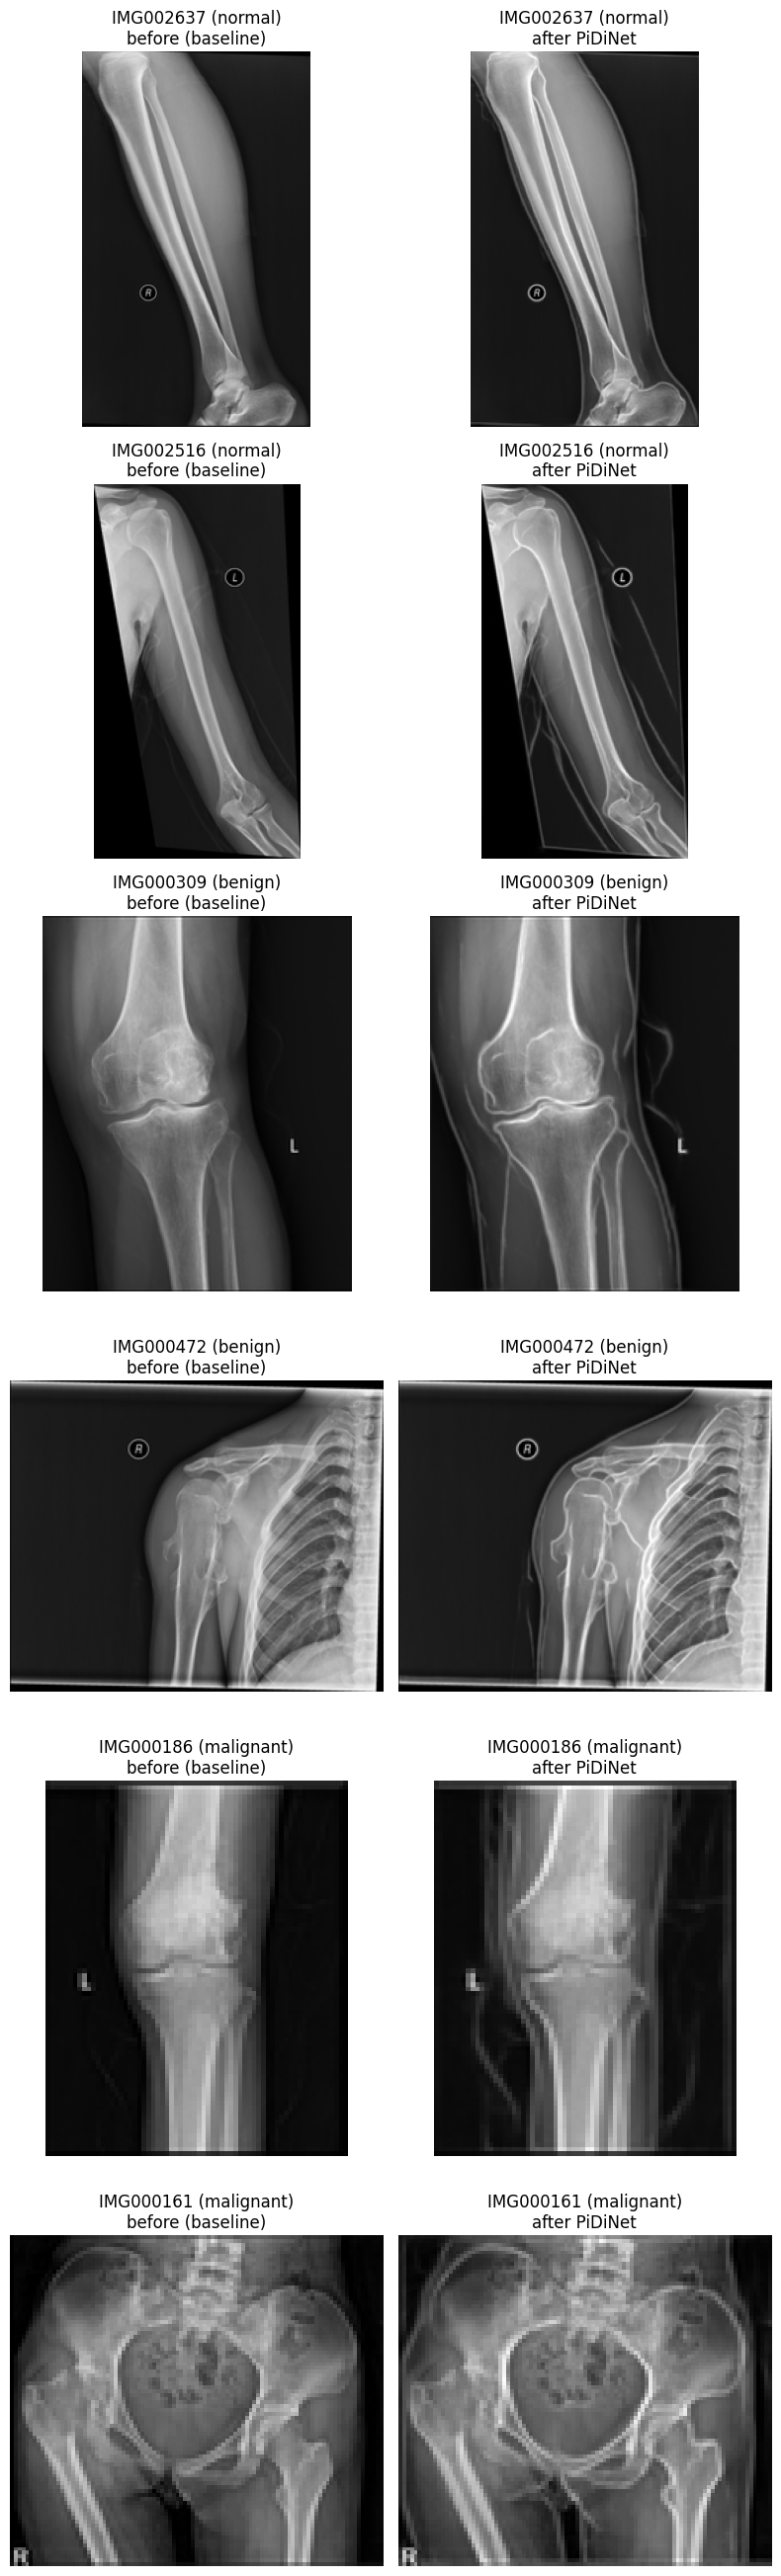

In [8]:
picks = pd.concat([images[images["group"] == group].sample(2, random_state=42)
                   for group in ["normal", "benign", "malignant"]])
titles = ["before (baseline)", "after PiDiNet"]

fig, axes = plt.subplots(len(picks), 2, figsize=(8, 4.4 * len(picks)))
for row, (_, pick) in zip(axes, picks.iterrows()):
    before = baseline(pick)                                    # the baseline image
    after = shrink(pidinet(load(pick['path'])))                # PiDiNet on the full image, then 512 x 512
    top, bottom, left, right = xray_box(before)                # cut away the black square, so the bone is big enough to see
    for ax, picture, title in zip(row, [before, after], titles):
        ax.imshow(picture[top:bottom, left:right], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{pick['image']} ({pick['group']})\n{title}")
        ax.axis("off")

plt.tight_layout()
plt.show()

## Measuring functions
The same functions as in the classical notebooks.
- PSNR and SSIM: how much the image changed (higher = less change). Measured on the X-ray only, not the black square.
- CII: how much more the tumor stands out from the ring around it. Above 1 = it stands out more.

In [9]:
def tumor_mask(name):
    annotation = json.loads((ANNOTATIONS / (name + ".json")).read_text())
    scale = SIZE[0] / annotation["imageWidth"]                 # the outline was drawn on the 2440 x 2440 image
    mask = np.zeros((SIZE[1], SIZE[0]), dtype=np.uint8)
    for shape in annotation["shapes"]:
        if shape["shape_type"] == "polygon":                   # the outline (the rectangles are only boxes)
            points = np.round(np.array(shape["points"]) * scale).astype(np.int32)
            cv2.fillPoly(mask, [points], 1)
    return mask == 1                                           # True inside the tumor


def ring_around(tumor, before):
    kernel = np.ones((2 * RING + 1, 2 * RING + 1), dtype=np.uint8)
    bigger = cv2.dilate(tumor.astype(np.uint8), kernel) == 1   # the tumor made RING pixels bigger
    return bigger & ~tumor & (before > BLACK)                  # the ring: not the tumor, not the black background


def contrast(image, tumor, ring):
    t = image[tumor].mean()                                    # tumor brightness
    r = image[ring].mean()                                     # ring brightness
    return abs(t - r) / (t + r)                                # abs: a tumor can be darker or brighter than the bone


def cii(before, after, tumor, ring):
    if tumor.sum() == 0 or ring.sum() == 0:
        return np.nan                                          # cannot be measured
    contrast_before = contrast(before, tumor, ring)
    if contrast_before == 0:
        return np.nan                                          # cannot divide by 0
    return contrast(after, tumor, ring) / contrast_before


def psnr_ssim(before, after):
    top, bottom, left, right = xray_box(before)                # the X-ray only
    a, b = before[top:bottom, left:right], after[top:bottom, left:right]
    return peak_signal_noise_ratio(a, b, data_range=255), structural_similarity(a, b, data_range=255)

## Measuring functions at full size
The same tumor outline and ring, but on the 2440 x 2440 image: the outline is not made smaller, and the ring is 48 pixels wide (the same area as the 10-pixel ring at 512 x 512), as in the classical `*_full_size_scores` notebooks.

In [10]:
def tumor_mask_full(name, size):
    annotation = json.loads((ANNOTATIONS / (name + ".json")).read_text())
    scale = size[1] / annotation["imageWidth"]                 # 1.0: the outline was drawn on the 2440 x 2440 image
    mask = np.zeros(size, dtype=np.uint8)
    for shape in annotation["shapes"]:
        if shape["shape_type"] == "polygon":                   # the outline (the rectangles are only boxes)
            points = np.round(np.array(shape["points"]) * scale).astype(np.int32)
            cv2.fillPoly(mask, [points], 1)
    return mask == 1                                           # True inside the tumor


def ring_around_full(tumor, before):
    kernel = np.ones((2 * RING_FULL + 1, 2 * RING_FULL + 1), dtype=np.uint8)
    bigger = cv2.dilate(tumor.astype(np.uint8), kernel) == 1   # the tumor made RING_FULL pixels bigger
    return bigger & ~tumor & (before > BLACK)                  # the ring: not the tumor, not the black background

## Make every image
For every image: PiDiNet on the full image, then 512 x 512, then saved as PNG in the Drive folder `BTXRD/BTXRD_pidinet_512_weight0-25`.
While the full-size result is there, its **full-size scores** are measured too (the full image after PiDiNet edge enhancement against the original full image) and saved as one line per image in `BTXRD/BTXRD_pidinet_512_weight0-25_full_size_scores.csv`. So the method runs only once.
Images that are already done are skipped, so after a disconnect this continues where it stopped.

In [11]:
def png_path(item):
    return OUT_DIR / item["split"] / item["label"] / (item["image"] + ".png")


def scored_images():
    if not FULL_SCORES.exists():
        return set()
    return set(pd.read_csv(FULL_SCORES)["image"])             # images that already have their full-size scores


scored = scored_images()
todo = [item for _, item in images.iterrows() if not png_path(item).exists() or item["image"] not in scored]
print(len(images) - len(todo), "images already done,", len(todo), "to do")

start = time.time()
for n, item in enumerate(todo, start=1):
    raw = load(item["path"])                                   # the original X-ray at full size
    full = pidinet(raw)                                        # PiDiNet on the full image (2440 x 2440)
    after = shrink(full)                                       # then 512 x 512

    psnr, ssim = psnr_ssim(raw, full)                          # full-size scores: the full image after the method vs the original
    row = {"image": item["image"], "label": item["label"], "PSNR": psnr, "SSIM": ssim, "CII": np.nan}
    if item["label"] == "tumor":
        tumor = tumor_mask_full(item["image"], raw.shape)
        row["CII"] = cii(raw, full, tumor, ring_around_full(tumor, raw))
    pd.DataFrame([row]).to_csv(FULL_SCORES, mode="a", header=not FULL_SCORES.exists(), index=False)   # one line per image, in Drive

    target = png_path(item)
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = target.with_suffix(".tmp")
    Image.fromarray(after).save(temporary, format="PNG")
    os.replace(temporary, target)                              # renamed only when complete, so a half-written image is never kept

    if n % 100 == 0 or n == len(todo):
        minutes_left = (time.time() - start) / n * (len(todo) - n) / 60
        print(f"{n} of {len(todo)} done, about {minutes_left:.0f} minutes left")

done = sum(1 for _, item in images.iterrows() if png_path(item).exists())
scored = scored_images()
print(done, "of", len(images), "images are in", OUT_DIR, "|", len(scored & set(images["image"])), "have full-size scores")
assert done == len(images) and set(images["image"]) <= scored, "not all images are done: run this cell again"

0 images already done, 3723 to do
100 of 3723 done, about 24 minutes left
200 of 3723 done, about 26 minutes left
300 of 3723 done, about 27 minutes left
400 of 3723 done, about 26 minutes left
500 of 3723 done, about 26 minutes left
600 of 3723 done, about 26 minutes left
700 of 3723 done, about 25 minutes left
800 of 3723 done, about 25 minutes left
900 of 3723 done, about 24 minutes left
1000 of 3723 done, about 23 minutes left
1100 of 3723 done, about 22 minutes left
1200 of 3723 done, about 21 minutes left
1300 of 3723 done, about 19 minutes left
1400 of 3723 done, about 18 minutes left
1500 of 3723 done, about 17 minutes left
1600 of 3723 done, about 17 minutes left
1700 of 3723 done, about 16 minutes left
1800 of 3723 done, about 15 minutes left
1900 of 3723 done, about 14 minutes left
2000 of 3723 done, about 14 minutes left
2100 of 3723 done, about 13 minutes left
2200 of 3723 done, about 12 minutes left
2300 of 3723 done, about 11 minutes left
2400 of 3723 done, about 10 minu

## Make the zip
Puts all images in `BTXRD_pidinet_512_weight0-25.zip` (`BTXRD_pidinet_512_weight0-25/split/label/name.png`), the same layout as `BTXRD_512.zip`, and also copies it to Drive.

In [12]:
with zipfile.ZipFile(NEW_ZIP, "w") as new_zip:                 # "w": makes a new zip (an old one with the same name is replaced)
    for _, item in images.iterrows():
        source = OUT_DIR / item["split"] / item["label"] / (item["image"] + ".png")
        new_zip.write(source, f"{NAME}/{item['split']}/{item['label']}/{item['image']}.png")

shutil.copy(NEW_ZIP, DRIVE / NEW_ZIP.name)                     # also keep the zip in Google Drive
print(len(images), "images saved in", NEW_ZIP, "and in", DRIVE / NEW_ZIP.name)

3723 images saved in /content/BTXRD_pidinet_512_weight0-25.zip and in /content/drive/MyDrive/BTXRD/BTXRD_pidinet_512_weight0-25.zip


## Check the new zip
Counts the images in each folder, checks that all are 512 x 512 gray images, and that every image is in the same split and label as in `BTXRD_512.zip`.

In [13]:
with zipfile.ZipFile(NEW_ZIP) as new_zip:
    files = [name for name in new_zip.namelist() if name.endswith(".png")]
    sizes, modes = Counter(), Counter()
    for name in files:
        image = Image.open(new_zip.open(name))
        sizes[image.size] += 1
        modes[image.mode] += 1                                 # L = gray

for folder, count in sorted(Counter(name.rsplit("/", 1)[0] for name in files).items()):
    print(folder, count)
print("Sizes:", dict(sizes), "| modes:", dict(modes))
new_names = {name.removeprefix(NAME + "/").removesuffix(".png") for name in files}
print("Same images, split and label as BTXRD_512.zip:", new_names == old_names)
print("Zip size:", round(NEW_ZIP.stat().st_size / 1e6), "MB")

BTXRD_pidinet_512_weight0-25/test/normal 280
BTXRD_pidinet_512_weight0-25/test/tumor 279
BTXRD_pidinet_512_weight0-25/train/normal 1306
BTXRD_pidinet_512_weight0-25/train/tumor 1300
BTXRD_pidinet_512_weight0-25/validation/normal 280
BTXRD_pidinet_512_weight0-25/validation/tumor 278
Sizes: {(512, 512): 3723} | modes: {'L': 3723}
Same images, split and label as BTXRD_512.zip: True
Zip size: 73 MB


## Measure every image at 512 x 512
PSNR, SSIM and CII of every image in the new zip against its baseline image, as in the classical notebooks. CII is only for tumor images.

In [14]:
rows = []
with zipfile.ZipFile(NEW_ZIP) as new_zip:
    for _, item in images.iterrows():
        before = baseline(item)                                # the baseline image
        after = np.array(Image.open(io.BytesIO(new_zip.read(f"{NAME}/{item['split']}/{item['label']}/{item['image']}.png"))))

        psnr, ssim = psnr_ssim(before, after)
        row = {"image": item["image"], "label": item["label"], "PSNR": psnr, "SSIM": ssim, "CII": np.nan}
        if item["label"] == "tumor":
            tumor = tumor_mask(item["image"])
            row["CII"] = cii(before, after, tumor, ring_around(tumor, before))
        rows.append(row)

scores = pd.DataFrame(rows)
print(len(scores), "images measured")

3723 images measured


## Results at 512 x 512
The middle value (median) of each score: the image after PiDiNet edge enhancement compared with the baseline image. CII only counts the tumor images.

In [15]:
scores[["PSNR", "SSIM", "CII"]].median().round(3)

,0
PSNR,24.631
SSIM,0.796
CII,0.898


## Results at full size
The middle value (median) of each score at full size: the full image after PiDiNet edge enhancement compared with the original full image. CII only counts the tumor images.

In [16]:
full_scores = pd.read_csv(FULL_SCORES).drop_duplicates("image", keep="last")   # one line per image (a disconnect can repeat one)
full_scores = full_scores[full_scores["image"].isin(images["image"])]
print(len(full_scores), "images with full-size scores")
assert len(full_scores) == len(images)
full_scores[["PSNR", "SSIM", "CII"]].median().round(3)

3723 images with full-size scores


,0
PSNR,24.487
SSIM,0.878
CII,0.886


## Download the zip and the full-size scores

In [17]:
from google.colab import files                                 # imported again: the zip check above uses the name "files" for its list

files.download(str(NEW_ZIP))                                   # or download both from the Google Drive folder BTXRD
files.download(str(FULL_SCORES))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>